In [1]:
import sys
print(sys.executable)

C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
import joblib

In [3]:
from pathlib import Path

project_path = Path.cwd().parent
data_path = project_path / "data" / "raw"

print("Project path:", project_path)
print("\nFiles available:")
for file in data_path.iterdir():
    print(file.name)

Project path: C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics

Files available:
customers.csv
orders.csv
order_items.csv
payments.csv
products.csv
refunds.csv


In [4]:
customers = pd.read_csv(data_path / "customers.csv")
orders = pd.read_csv(data_path / "orders.csv")
order_items = pd.read_csv(data_path / "order_items.csv")
products = pd.read_csv(data_path / "products.csv")
payments = pd.read_csv(data_path / "payments.csv")
refunds = pd.read_csv(data_path / "refunds.csv")

In [5]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Payments": payments,
    "Refunds": refunds
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (20000, 5)
Orders: (100000, 9)
Order Items: (237537, 7)
Products: (1200, 6)
Payments: (105388, 6)
Refunds: (7910, 6)


In [6]:
for name, df in datasets.items():
    print(f"\n{'='*40}")
    print(name)
    print('='*40)
    print(df.columns.tolist())


Customers
['customer_id', 'created_at', 'country_code', 'acquisition_channel', 'customer_segment']

Orders
['order_id', 'customer_id', 'ordered_at', 'order_status', 'currency', 'subtotal', 'tax_amount', 'shipping_amount', 'order_total']

Order Items
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'discount_amount', 'line_total']

Products
['product_id', 'sku', 'product_name', 'category', 'unit_cost', 'list_price']

Payments
['payment_id', 'order_id', 'paid_at', 'payment_method', 'payment_status', 'amount']

Refunds
['refund_id', 'payment_id', 'order_id', 'refunded_at', 'refund_reason', 'amount']


In [7]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Missing values:")
    print(df.isnull().sum().sum())
    print("\nData types:")
    print(df.dtypes)


--- Customers ---
Missing values:
0

Data types:
customer_id            str
created_at             str
country_code           str
acquisition_channel    str
customer_segment       str
dtype: object

--- Orders ---
Missing values:
0

Data types:
order_id               str
customer_id            str
ordered_at             str
order_status           str
currency               str
subtotal           float64
tax_amount         float64
shipping_amount    float64
order_total        float64
dtype: object

--- Order Items ---
Missing values:
0

Data types:
order_item_id          str
order_id               str
product_id             str
quantity             int64
unit_price         float64
discount_amount    float64
line_total         float64
dtype: object

--- Products ---
Missing values:
0

Data types:
product_id          str
sku                 str
product_name        str
category            str
unit_cost       float64
list_price      float64
dtype: object

--- Payments ---
Missing values:
0

In [8]:
customers["created_at"] = pd.to_datetime(customers["created_at"])
orders["ordered_at"] = pd.to_datetime(orders["ordered_at"])
payments["paid_at"] = pd.to_datetime(payments["paid_at"])
refunds["refunded_at"] = pd.to_datetime(refunds["refunded_at"])

print("Date columns converted successfully!")

Date columns converted successfully!


In [9]:
orders["ordered_at"].dtype

datetime64[us, UTC]

In [10]:
for name, df in datasets.items():
    duplicates = df.duplicated().sum()
    print(f"{name}: {duplicates} duplicate rows")

Customers: 0 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Payments: 0 duplicate rows
Refunds: 0 duplicate rows


In [11]:
customer_orders = (
    orders[orders["order_status"].str.lower() != "cancelled"]
    .groupby("customer_id")["order_id"]
    .nunique()
)

print(customer_orders.describe())

count    19850.000000
mean         4.887859
std          2.217713
min          1.000000
25%          3.000000
50%          5.000000
75%          6.000000
max         16.000000
Name: order_id, dtype: float64


In [12]:
customer_spending = (
    orders[orders["order_status"].str.lower() != "cancelled"]
    .groupby("customer_id")["order_total"]
    .sum()
)

customer_spending.head()


customer_id
C000001    2003.88
C000002    2815.73
C000003    3812.00
C000004    6660.78
C000005    3245.15
Name: order_total, dtype: float64

In [13]:
customer_features = pd.concat(
    [customer_orders, customer_spending],
    axis=1
)

customer_features.columns = [
    "total_orders",
    "total_spending"
]

customer_features.head()

,total_orders,total_spending
customer_id,,
C000001,3,2003.88
C000002,9,2815.73
C000003,6,3812.00
C000004,7,6660.78
C000005,8,3245.15


In [14]:
customer_features["average_order_value"] = (
    customer_features["total_spending"] / customer_features["total_orders"]
)

customer_features.head()

,total_orders,total_spending,average_order_value
customer_id,,,
C000001,3,2003.88,667.960000
C000002,9,2815.73,312.858889
C000003,6,3812.00,635.333333
C000004,7,6660.78,951.540000
C000005,8,3245.15,405.643750


In [15]:
customer_last_purchase = (
    orders[orders["order_status"].str.lower() != "cancelled"]
    .groupby("customer_id")["ordered_at"]
    .max()
)

customer_features["last_purchase_date"] = customer_last_purchase

customer_features.head()

,total_orders,total_spending,average_order_value,last_purchase_date
customer_id,,,,
C000001,3,2003.88,667.960000,2024-11-27 21:37:49+00:00
C000002,9,2815.73,312.858889,2025-09-28 06:21:32+00:00
C000003,6,3812.00,635.333333,2025-12-28 05:23:37+00:00
C000004,7,6660.78,951.540000,2025-12-25 00:44:01+00:00
C000005,8,3245.15,405.643750,2025-07-18 03:49:50+00:00


In [16]:
analysis_date = orders["ordered_at"].max()

customer_features["recency_days"] = (
    analysis_date - customer_features["last_purchase_date"]
).dt.days

customer_features.head()

,total_orders,total_spending,average_order_value,last_purchase_date,recency_days
customer_id,,,,,
C000001,3,2003.88,667.960000,2024-11-27 21:37:49+00:00,399
C000002,9,2815.73,312.858889,2025-09-28 06:21:32+00:00,94
C000003,6,3812.00,635.333333,2025-12-28 05:23:37+00:00,3
C000004,7,6660.78,951.540000,2025-12-25 00:44:01+00:00,6
C000005,8,3245.15,405.643750,2025-07-18 03:49:50+00:00,166


In [17]:
customer_features = customer_features.merge(
    customers[[
        "customer_id",
        "acquisition_channel",
        "customer_segment",
        "country_code"
    ]],
    on="customer_id",
    how="left"
)

customer_features.head()

,customer_id,total_orders,total_spending,average_order_value,last_purchase_date,recency_days,acquisition_channel,customer_segment,country_code
0,C000001,3,2003.88,667.960000,2024-11-27 21:37:49+00:00,399,organic,consumer,DE
1,C000002,9,2815.73,312.858889,2025-09-28 06:21:32+00:00,94,paid_search,small_business,US
2,C000003,6,3812.00,635.333333,2025-12-28 05:23:37+00:00,3,paid_social,consumer,US
3,C000004,7,6660.78,951.540000,2025-12-25 00:44:01+00:00,6,affiliate,small_business,US
4,C000005,8,3245.15,405.643750,2025-07-18 03:49:50+00:00,166,organic,consumer,GB


In [19]:
customers["created_at"] = pd.to_datetime(
    customers["created_at"],
    utc=True
)

In [21]:
print(customer_features.columns.tolist())

['customer_id', 'total_orders', 'total_spending', 'average_order_value', 'last_purchase_date', 'recency_days', 'acquisition_channel', 'customer_segment', 'country_code', 'created_at_x', 'created_at_y']


In [22]:
customer_features = customer_features.drop(
    columns=["created_at_x", "created_at_y"],
    errors="ignore"
)

In [23]:
customer_features = customer_features.merge(
    customers[["customer_id", "created_at"]],
    on="customer_id",
    how="left"
)

In [24]:
customer_features["tenure_days"] = (
    analysis_date - customer_features["created_at"]
).dt.days

customer_features.head()

,customer_id,total_orders,total_spending,average_order_value,last_purchase_date,recency_days,acquisition_channel,customer_segment,country_code,created_at,tenure_days
0,C000001,3,2003.88,667.960000,2024-11-27 21:37:49+00:00,399,organic,consumer,DE,2023-01-01 00:00:00+00:00,1095
1,C000002,9,2815.73,312.858889,2025-09-28 06:21:32+00:00,94,paid_search,small_business,US,2023-01-01 00:00:00+00:00,1095
2,C000003,6,3812.00,635.333333,2025-12-28 05:23:37+00:00,3,paid_social,consumer,US,2023-01-01 00:00:00+00:00,1095
3,C000004,7,6660.78,951.540000,2025-12-25 00:44:01+00:00,6,affiliate,small_business,US,2023-01-01 00:00:00+00:00,1095
4,C000005,8,3245.15,405.643750,2025-07-18 03:49:50+00:00,166,organic,consumer,GB,2023-01-01 00:00:00+00:00,1095


In [25]:
customer_features[
    [
        "total_orders",
        "total_spending",
        "average_order_value",
        "recency_days",
        "tenure_days"
    ]
].describe()

,total_orders,total_spending,average_order_value,recency_days,tenure_days
count,19850.000000,19850.000000,19850.000000,19850.000000,19850.000000
mean,4.887859,3196.904920,653.196145,215.335919,1050.038136
std,2.217713,1808.215128,252.740763,203.936640,26.279876
min,1.000000,20.140000,20.140000,0.000000,1005.000000
25%,3.000000,1858.765000,484.970750,63.000000,1027.000000
50%,5.000000,2956.830000,628.479750,152.500000,1050.000000
75%,6.000000,4250.355000,791.370833,304.750000,1073.000000
max,16.000000,13836.620000,2633.450000,1095.000000,1095.000000


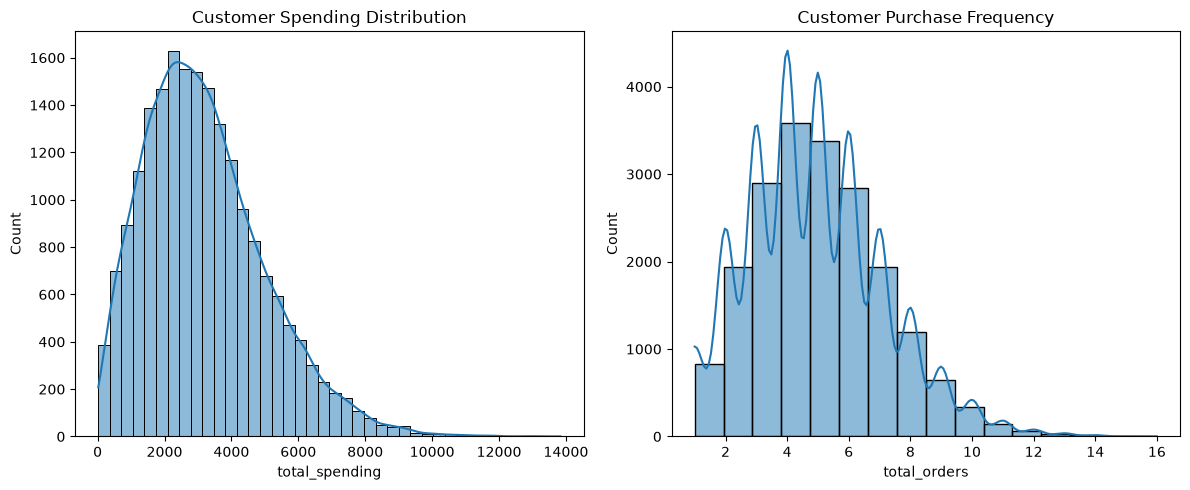

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(customer_features["total_spending"], bins=40, kde=True)
plt.title("Customer Spending Distribution")

plt.subplot(1, 2, 2)
sns.histplot(customer_features["total_orders"], bins=16, kde=True)
plt.title("Customer Purchase Frequency")

plt.tight_layout()
plt.show()

In [27]:
customer_features[
    ["total_orders", "total_spending", "average_order_value", "recency_days"]
].skew()

total_orders           0.541234
total_spending         0.797233
average_order_value    0.890541
recency_days           1.502930
dtype: float64

In [28]:
customer_features["spending_log"] = np.log1p(
    customer_features["total_spending"]
)

customer_features["recency_log"] = np.log1p(
    customer_features["recency_days"]
)

In [29]:
customer_features[
    ["total_spending", "spending_log",
     "recency_days", "recency_log"]
].skew()

total_spending    0.797233
spending_log     -1.424613
recency_days      1.502930
recency_log      -0.940233
dtype: float64

In [30]:
from sklearn.preprocessing import RobustScaler

rfm_features = customer_features[
    ["recency_days", "total_orders", "total_spending"]
].copy()

scaler = RobustScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=rfm_features.columns
)

rfm_scaled.head()

,recency_days,total_orders,total_spending
0,1.019648,-0.666667,-0.398459
1,-0.241986,1.333333,-0.058998
2,-0.618407,0.333333,0.357574
3,-0.605998,0.666667,1.548740
4,0.055843,1.000000,0.120556


In [31]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

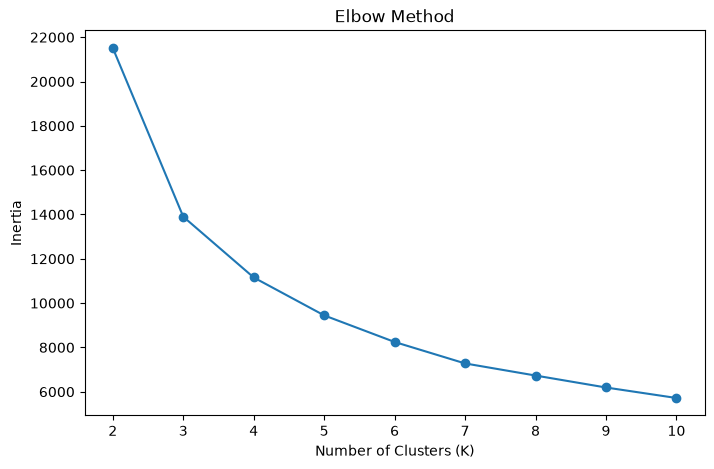

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [33]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3502
K = 3, Silhouette Score = 0.3711
K = 4, Silhouette Score = 0.3119
K = 5, Silhouette Score = 0.3153
K = 6, Silhouette Score = 0.3040
K = 7, Silhouette Score = 0.2815
K = 8, Silhouette Score = 0.2744
K = 9, Silhouette Score = 0.2817
K = 10, Silhouette Score = 0.2689


In [34]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_features["cluster"] = kmeans.fit_predict(rfm_scaled)

customer_features[["total_orders", "total_spending",
                   "recency_days", "cluster"]].head()

,total_orders,total_spending,recency_days,cluster
0,3,2003.88,399,1
1,9,2815.73,94,0
2,6,3812.00,3,0
3,7,6660.78,6,0
4,8,3245.15,166,0


In [35]:
cluster_summary = customer_features.groupby("cluster").agg(
    customer_count=("total_orders", "count"),
    avg_orders=("total_orders", "mean"),
    avg_spending=("total_spending", "mean"),
    avg_recency=("recency_days", "mean"),
    avg_order_value=("average_order_value", "mean")
).round(2)

cluster_summary

,customer_count,avg_orders,avg_spending,avg_recency,avg_order_value
cluster,,,,,
0,6418,7.30,5191.13,127.76,728.78
1,3477,2.88,1812.12,571.39,635.87
2,9955,4.04,2394.89,147.44,610.52


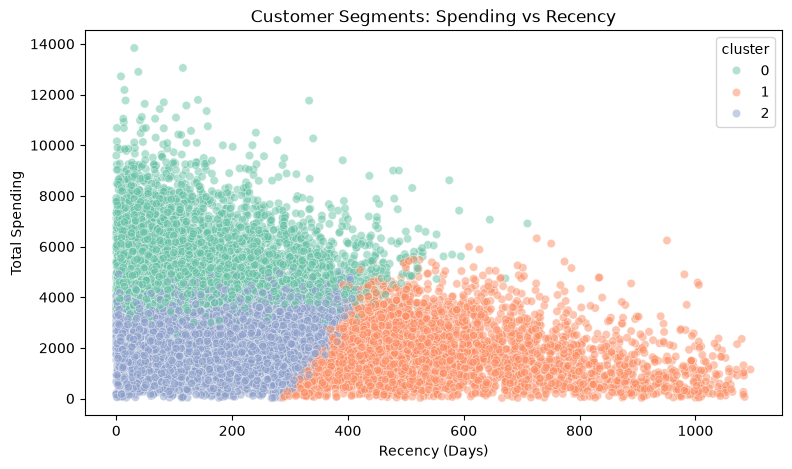

In [36]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=customer_features,
    x="recency_days",
    y="total_spending",
    hue="cluster",
    palette="Set2",
    alpha=0.5
)

plt.title("Customer Segments: Spending vs Recency")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Spending")
plt.show()

In [37]:
cluster_names = {
    0: "High Value Frequent Customers",
    1: "At Risk Customers",
    2: "Regular Customers"
}

customer_features["cluster_name"] = (
    customer_features["cluster"].map(cluster_names)
)

customer_features[
    ["customer_id", "total_orders", "total_spending",
     "recency_days", "cluster_name"]
].head(10)

,customer_id,total_orders,total_spending,recency_days,cluster_name
0,C000001,3,2003.88,399,At Risk Customers
1,C000002,9,2815.73,94,High Value Frequent Customers
2,C000003,6,3812.00,3,High Value Frequent Customers
3,C000004,7,6660.78,6,High Value Frequent Customers
4,C000005,8,3245.15,166,High Value Frequent Customers
5,C000006,3,2029.93,251,Regular Customers
6,C000007,7,6453.48,7,High Value Frequent Customers
7,C000008,8,8081.93,68,High Value Frequent Customers
8,C000009,4,2333.75,6,Regular Customers
9,C000010,8,5016.87,242,High Value Frequent Customers


In [38]:
customer_features["cluster_name"].value_counts()

cluster_name
Regular Customers                9955
High Value Frequent Customers    6418
At Risk Customers                3477
Name: count, dtype: int64

In [39]:
orders["ordered_at"].min(), orders["ordered_at"].max()

(Timestamp('2023-01-01 00:27:20+0000', tz='UTC'),
 Timestamp('2025-12-31 23:59:03+0000', tz='UTC'))

In [40]:
cutoff_date = pd.Timestamp("2025-10-03", tz="UTC")

prediction_end = cutoff_date + pd.Timedelta(days=90)

print("Feature cutoff:", cutoff_date)
print("Prediction window ends:", prediction_end)

Feature cutoff: 2025-10-03 00:00:00+00:00
Prediction window ends: 2026-01-01 00:00:00+00:00


In [42]:
historical_orders = orders[
    (orders["ordered_at"] < cutoff_date) &
    (orders["order_status"].str.lower() != "cancelled")
].copy()

# Future data: used only to create the prediction target
future_orders = orders[
    (orders["ordered_at"] >= cutoff_date) &
    (orders["ordered_at"] < prediction_end) &
    (orders["order_status"].str.lower() != "cancelled")
].copy()

print("Historical orders:", len(historical_orders))
print("Future orders:", len(future_orders))

Historical orders: 89024
Future orders: 8000


In [43]:
# Identify customers who purchased during the future window
future_purchasers = future_orders["customer_id"].unique()

# Include all 20,000 customers
prediction_data = customers[["customer_id"]].copy()

# Create the target column
prediction_data["repeat_purchase"] = (
    prediction_data["customer_id"].isin(future_purchasers).astype(int)
)

prediction_data["repeat_purchase"].value_counts()

repeat_purchase
0    13370
1     6630
Name: count, dtype: int64

In [44]:
historical_features = historical_orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    total_spending=("order_total", "sum"),
    last_purchase_date=("ordered_at", "max")
).reset_index()

historical_features["average_order_value"] = (
    historical_features["total_spending"] /
    historical_features["total_orders"]
)

historical_features["recency_days"] = (
    cutoff_date - historical_features["last_purchase_date"]
).dt.days

In [45]:
# Add registration date
historical_features = historical_features.merge(
    customers[["customer_id", "created_at"]],
    on="customer_id",
    how="right"
)

# Calculate customer tenure at the cutoff date
historical_features["tenure_days"] = (
    cutoff_date - historical_features["created_at"]
).dt.days

# Identify customers with no historical purchases
historical_features["has_prior_purchase"] = (
    historical_features["total_orders"].notna().astype(int)
)

# Fill missing purchase information
historical_features["total_orders"] = (
    historical_features["total_orders"].fillna(0)
)

historical_features["total_spending"] = (
    historical_features["total_spending"].fillna(0)
)

historical_features["average_order_value"] = (
    historical_features["average_order_value"].fillna(0)
)

# For customers without purchases, use tenure as a recency proxy
historical_features["recency_days"] = (
    historical_features["recency_days"].fillna(
        historical_features["tenure_days"]
    )
)

In [46]:
prediction_data = historical_features.merge(
    prediction_data,
    on="customer_id",
    how="inner"
)

prediction_data.head()

,customer_id,total_orders,total_spending,last_purchase_date,average_order_value,recency_days,created_at,tenure_days,has_prior_purchase,repeat_purchase
0,C000001,3.0,2003.88,2024-11-27 21:37:49+00:00,667.960000,309.0,2023-01-01 00:00:00+00:00,1006,1,0
1,C000002,9.0,2815.73,2025-09-28 06:21:32+00:00,312.858889,4.0,2023-01-01 00:00:00+00:00,1006,1,0
2,C000003,5.0,1701.96,2025-06-11 23:06:21+00:00,340.392000,113.0,2023-01-01 00:00:00+00:00,1006,1,1
3,C000004,5.0,6097.86,2024-05-30 05:13:55+00:00,1219.572000,490.0,2023-01-01 00:00:00+00:00,1006,1,1
4,C000005,8.0,3245.15,2025-07-18 03:49:50+00:00,405.643750,76.0,2023-01-01 00:00:00+00:00,1006,1,0


In [47]:
print("Dataset shape:", prediction_data.shape)
print("\nMissing values:")
print(prediction_data.isnull().sum())

Dataset shape: (20000, 10)

Missing values:
customer_id              0
total_orders             0
total_spending           0
last_purchase_date     230
average_order_value      0
recency_days             0
created_at               0
tenure_days              0
has_prior_purchase       0
repeat_purchase          0
dtype: int64


In [48]:
# Select model input features
feature_columns = [
    "total_orders",
    "total_spending",
    "average_order_value",
    "recency_days",
    "tenure_days",
    "has_prior_purchase"
]

X = prediction_data[feature_columns]

# Prediction target
y = prediction_data["repeat_purchase"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Missing feature values:", X.isnull().sum().sum())

Features shape: (20000, 6)
Target shape: (20000,)
Missing feature values: 0


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (16000, 6)
Testing features: (4000, 6)

Training target distribution:
repeat_purchase
0    0.6685
1    0.3315
Name: proportion, dtype: float64

Testing target distribution:
repeat_purchase
0    0.6685
1    0.3315
Name: proportion, dtype: float64


In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (16000, 6)
Testing data shape: (4000, 6)


In [51]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [52]:
y_pred = model.predict(X_test_scaled)

print("First 20 actual values:")
print(y_test.values[:20])

print("\nFirst 20 predicted values:")
print(y_pred[:20])

First 20 actual values:
[0 0 1 1 1 0 0 0 0 0 0 1 0 1 0 1 1 0 0 0]

First 20 predicted values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [53]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6685

Confusion Matrix:
[[2674    0]
 [1326    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      1.00      0.80      2674
           1       0.00      0.00      0.00      1326

    accuracy                           0.67      4000
   macro avg       0.33      0.50      0.40      4000
weighted avg       0.45      0.67      0.54      4000



C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_divisio

In [54]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Minimum probability:", y_prob.min())
print("Maximum probability:", y_prob.max())
print("Average probability:", y_prob.mean())

print("\nProbability percentiles:")
print(np.percentile(y_prob, [25, 50, 75, 90, 95, 99]))

Minimum probability: 0.30877774564301047
Maximum probability: 0.38944211947218993
Average probability: 0.33178205784449355

Probability percentiles:
[0.32369129 0.32996486 0.33753248 0.3459255  0.35169191 0.38461459]


In [55]:
balanced_model = LogisticRegression(
    random_state=42,
    class_weight="balanced",
    max_iter=1000
)

balanced_model.fit(X_train_scaled, y_train)

balanced_pred = balanced_model.predict(X_test_scaled)

print(classification_report(y_test, balanced_pred))

              precision    recall  f1-score   support

           0       0.67      0.55      0.61      2674
           1       0.33      0.44      0.38      1326

    accuracy                           0.52      4000
   macro avg       0.50      0.50      0.49      4000
weighted avg       0.56      0.52      0.53      4000



In [56]:
print("Original Logistic Regression:")
print(confusion_matrix(y_test, y_pred))

print("\nBalanced Logistic Regression:")
print(confusion_matrix(y_test, balanced_pred))

Original Logistic Regression:
[[2674    0]
 [1326    0]]

Balanced Logistic Regression:
[[1484 1190]
 [ 736  590]]


In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

balanced_prob = balanced_model.predict_proba(X_test_scaled)[:, 1]

for threshold in [0.35, 0.40, 0.45, 0.50]:
    threshold_pred = (balanced_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, threshold_pred), 3))
    print("Recall:", round(recall_score(y_test, threshold_pred), 3))
    print("F1-score:", round(f1_score(y_test, threshold_pred), 3))


Threshold: 0.35
Precision: 0.332
Recall: 1.0
F1-score: 0.498

Threshold: 0.4
Precision: 0.332
Recall: 1.0
F1-score: 0.498

Threshold: 0.45
Precision: 0.332
Recall: 1.0
F1-score: 0.498

Threshold: 0.5
Precision: 0.331
Recall: 0.445
F1-score: 0.38


Minimum: 0.47377494888342747
Maximum: 0.5627457668910691
Mean: 0.5001975858839272


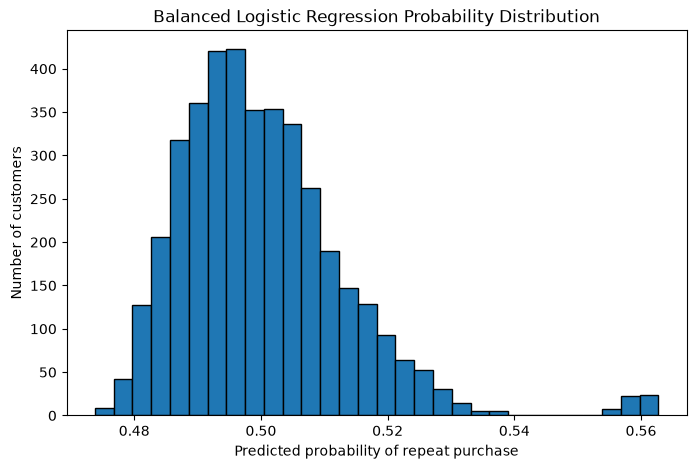

In [58]:
print("Minimum:", balanced_prob.min())
print("Maximum:", balanced_prob.max())
print("Mean:", balanced_prob.mean())

plt.figure(figsize=(8, 5))
plt.hist(balanced_prob, bins=30, edgecolor="black")
plt.xlabel("Predicted probability of repeat purchase")
plt.ylabel("Number of customers")
plt.title("Balanced Logistic Regression Probability Distribution")
plt.show()

In [59]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5,
    class_weight="balanced"
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print(classification_report(y_test, tree_pred))

              precision    recall  f1-score   support

           0       0.67      0.63      0.65      2674
           1       0.33      0.37      0.35      1326

    accuracy                           0.54      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.56      0.54      0.55      4000



In [60]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.66      0.56      0.61      2674
           1       0.32      0.42      0.36      1326

    accuracy                           0.52      4000
   macro avg       0.49      0.49      0.49      4000
weighted avg       0.55      0.52      0.53      4000



In [61]:
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance)

               feature  importance
3         recency_days    0.254004
1       total_spending    0.249584
2  average_order_value    0.236720
4          tenure_days    0.179424
0         total_orders    0.078316
5   has_prior_purchase    0.001952


In [62]:
correlation_matrix = prediction_data[feature_columns].corr()

print(correlation_matrix.round(2))

                     total_orders  total_spending  average_order_value  \
total_orders                 1.00            0.81                 0.06   
total_spending               0.81            1.00                 0.54   
average_order_value          0.06            0.54                 1.00   
recency_days                -0.46           -0.37                -0.09   
tenure_days                  0.17            0.14                 0.02   
has_prior_purchase           0.22            0.18                 0.25   

                     recency_days  tenure_days  has_prior_purchase  
total_orders                -0.46         0.17                0.22  
total_spending              -0.37         0.14                0.18  
average_order_value         -0.09         0.02                0.25  
recency_days                 1.00        -0.01               -0.37  
tenure_days                 -0.01         1.00                0.03  
has_prior_purchase          -0.37         0.03                1.00 

In [63]:
print("Acquisition channels:")
print(customers["acquisition_channel"].value_counts())

print("\nCustomer segments:")
print(customers["customer_segment"].value_counts())

print("\nCountries:")
print(customers["country_code"].nunique())

Acquisition channels:
acquisition_channel
organic        6117
paid_search    4994
paid_social    3932
referral       2920
affiliate      2037
Name: count, dtype: int64

Customer segments:
customer_segment
consumer          16407
small_business     2989
enterprise          604
Name: count, dtype: int64

Countries:
5


In [64]:
categorical_features = customers[
    ["customer_id", "acquisition_channel", "customer_segment", "country_code"]
]

enhanced_data = prediction_data.merge(
    categorical_features,
    on="customer_id",
    how="left"
)

print(enhanced_data.shape)
print(enhanced_data[
    ["acquisition_channel", "customer_segment", "country_code"]
].head())

(20000, 13)
  acquisition_channel customer_segment country_code
0             organic         consumer           DE
1         paid_search   small_business           US
2         paid_social         consumer           US
3           affiliate   small_business           US
4             organic         consumer           GB


In [65]:
numeric_features = [
    "total_orders",
    "total_spending",
    "average_order_value",
    "recency_days",
    "tenure_days",
    "has_prior_purchase"
]

categorical_columns = [
    "acquisition_channel",
    "customer_segment",
    "country_code"
]

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_columns))

Numerical features: 6
Categorical features: 3


In [66]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [67]:
X = enhanced_data[numeric_features + categorical_columns]
y = enhanced_data["repeat_purchase"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20000, 9)
Target shape: (20000,)


In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (16000, 9)
Testing: (4000, 9)


In [69]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

In [70]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training processed:", X_train_processed.shape)
print("Testing processed:", X_test_processed.shape)

Training processed: (16000, 19)
Testing processed: (4000, 19)


In [71]:
from sklearn.linear_model import LogisticRegression

categorical_logistic_model = LogisticRegression(
    random_state=42,
    class_weight="balanced",
    max_iter=1000
)

categorical_logistic_model.fit(
    X_train_processed,
    y_train
)

categorical_pred = categorical_logistic_model.predict(
    X_test_processed
)

In [72]:
from sklearn.metrics import classification_report

print(classification_report(y_test, categorical_pred))

              precision    recall  f1-score   support

           0       0.66      0.47      0.55      2674
           1       0.32      0.51      0.40      1326

    accuracy                           0.48      4000
   macro avg       0.49      0.49      0.47      4000
weighted avg       0.55      0.48      0.50      4000



In [73]:
from sklearn.metrics import roc_auc_score

categorical_prob = categorical_logistic_model.predict_proba(
    X_test_processed
)[:, 1]

auc_score = roc_auc_score(y_test, categorical_prob)

print("ROC-AUC:", round(auc_score, 4))

ROC-AUC: 0.4862


In [74]:
print("Probability statistics:")
print(pd.Series(categorical_prob).describe())

print("\nActual target distribution:")
print(y_test.value_counts(normalize=True))

print("\nPredicted target distribution:")
print(pd.Series(categorical_pred).value_counts(normalize=True))

Probability statistics:
count    4000.000000
mean        0.499926
std         0.021375
min         0.423018
25%         0.486875
50%         0.500851
75%         0.513272
max         0.597363
dtype: float64

Actual target distribution:
repeat_purchase
0    0.6685
1    0.3315
Name: proportion, dtype: float64

Predicted target distribution:
1    0.52125
0    0.47875
Name: proportion, dtype: float64


In [75]:
unbalanced_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

unbalanced_model.fit(X_train_processed, y_train)

unbalanced_prob = unbalanced_model.predict_proba(
    X_test_processed
)[:, 1]

unbalanced_auc = roc_auc_score(y_test, unbalanced_prob)

print("Balanced model AUC:", round(auc_score, 4))
print("Unbalanced model AUC:", round(unbalanced_auc, 4))

Balanced model AUC: 0.4862
Unbalanced model AUC: 0.4862


In [76]:
feature_analysis = enhanced_data.groupby("repeat_purchase")[
    numeric_features
].mean().T

feature_analysis.columns = [
    "Non_Repeat",
    "Repeat"
]

feature_analysis["Difference"] = (
    feature_analysis["Repeat"] -
    feature_analysis["Non_Repeat"]
)

print(feature_analysis.round(2))

                     Non_Repeat   Repeat  Difference
total_orders               4.45     4.46        0.01
total_spending          2901.11  2935.58       34.47
average_order_value      644.59   650.13        5.54
recency_days             220.85   225.60        4.75
tenure_days              961.13   960.75       -0.38
has_prior_purchase         0.99     0.99       -0.00


In [77]:
future_orders["order_month"] = (
    future_orders["ordered_at"].dt.to_period("M")
)

print(
    future_orders.groupby("order_month")["customer_id"]
    .nunique()
)

order_month
2025-10    2437
2025-11    2465
2025-12    2594
Freq: M, Name: customer_id, dtype: int64


C:\Users\AYUSH KUMAR\AppData\Local\Temp\ipykernel_16576\4057042508.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  future_orders["ordered_at"].dt.to_period("M")


In [78]:
historical_orders["days_before_cutoff"] = (
    cutoff_date - historical_orders["ordered_at"]
).dt.days

recent_orders = historical_orders[
    historical_orders["days_before_cutoff"] <= 90
]

recent_features = recent_orders.groupby("customer_id").agg(
    orders_last_90_days=("order_id", "nunique"),
    spending_last_90_days=("order_total", "sum")
).reset_index()

print(recent_features.head())
print("Customers with recent orders:", len(recent_features))

  customer_id  orders_last_90_days  spending_last_90_days
0     C000002                    1                 409.00
1     C000005                    1                 450.36
2     C000007                    2                1622.51
3     C000012                    1                 751.14
4     C000016                    2                1235.71
Customers with recent orders: 6662


In [79]:
enhanced_data = enhanced_data.merge(
    recent_features,
    on="customer_id",
    how="left"
)

enhanced_data[
    ["orders_last_90_days", "spending_last_90_days"]
] = enhanced_data[
    ["orders_last_90_days", "spending_last_90_days"]
].fillna(0)

print(enhanced_data.shape)

print(
    enhanced_data[
        ["orders_last_90_days", "spending_last_90_days"]
    ].describe().round(2)
)

(20000, 15)
       orders_last_90_days  spending_last_90_days
count             20000.00               20000.00
mean                  0.40                 263.13
std                   0.63                 513.87
min                   0.00                   0.00
25%                   0.00                   0.00
50%                   0.00                   0.00
75%                   1.00                 338.66
max                   4.00                5234.72


In [80]:
numeric_features = [
    "total_orders",
    "total_spending",
    "average_order_value",
    "recency_days",
    "tenure_days",
    "has_prior_purchase",
    "orders_last_90_days",
    "spending_last_90_days"
]

categorical_columns = [
    "acquisition_channel",
    "customer_segment",
    "country_code"
]

X = enhanced_data[numeric_features + categorical_columns]
y = enhanced_data["repeat_purchase"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (20000, 11)
Target: (20000,)


In [81]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (16000, 11)
Testing: (4000, 11)


In [82]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training:", X_train_processed.shape)
print("Processed testing:", X_test_processed.shape)

Processed training: (16000, 21)
Processed testing: (4000, 21)


In [83]:
improved_model = LogisticRegression(
    random_state=42,
    class_weight="balanced",
    max_iter=1000
)

improved_model.fit(X_train_processed, y_train)

improved_pred = improved_model.predict(X_test_processed)

improved_prob = improved_model.predict_proba(
    X_test_processed
)[:, 1]

In [84]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, improved_pred))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, improved_prob), 4)
)

              precision    recall  f1-score   support

           0       0.66      0.48      0.56      2674
           1       0.32      0.50      0.39      1326

    accuracy                           0.49      4000
   macro avg       0.49      0.49      0.48      4000
weighted avg       0.55      0.49      0.50      4000

ROC-AUC: 0.4857


In [85]:
recent_analysis = X_train.copy()

recent_analysis["repeat_purchase"] = y_train

recent_purchase_rate = (
    recent_analysis.groupby("orders_last_90_days")["repeat_purchase"]
    .agg(["count", "mean"])
)

recent_purchase_rate["mean"] = (
    recent_purchase_rate["mean"] * 100
)

print(recent_purchase_rate.round(2))

                     count   mean
orders_last_90_days              
0.0                  10642  33.31
1.0                   4348  32.73
2.0                    879  33.79
3.0                    120  29.17
4.0                     11  36.36


In [86]:
customer_order_dates = historical_orders[
    ["customer_id", "ordered_at"]
].drop_duplicates()

customer_order_dates = customer_order_dates.sort_values(
    ["customer_id", "ordered_at"]
)

customer_order_dates["days_between_orders"] = (
    customer_order_dates.groupby("customer_id")["ordered_at"]
    .diff()
    .dt.days
)

purchase_gap = customer_order_dates.groupby("customer_id").agg(
    average_days_between_orders=("days_between_orders", "mean")
).reset_index()

print(purchase_gap.head())

  customer_id  average_days_between_orders
0     C000001                      347.000
1     C000002                      124.375
2     C000003                      107.250
3     C000004                      128.250
4     C000005                      132.000


In [87]:
print("Customers with purchase-gap data:", len(purchase_gap))

print("\nPurchase-gap statistics:")
print(
    purchase_gap["average_days_between_orders"]
    .describe()
    .round(2)
)

Customers with purchase-gap data: 19770

Purchase-gap statistics:
count    18643.00
mean       193.74
std        122.75
min          0.00
25%        118.67
50%        162.00
75%        230.75
max        961.00
Name: average_days_between_orders, dtype: float64


In [88]:
enhanced_data = enhanced_data.merge(
    purchase_gap,
    on="customer_id",
    how="left"
)

print("Dataset shape:", enhanced_data.shape)

print(
    "Missing purchase gaps:",
    enhanced_data["average_days_between_orders"].isna().sum()
)

Dataset shape: (20000, 16)
Missing purchase gaps: 1357


In [89]:
missing_gap_customers = enhanced_data[
    enhanced_data["average_days_between_orders"].isna()
]

print("Missing gap customers:", len(missing_gap_customers))

print(
    "Customers with prior purchases:",
    missing_gap_customers["total_orders"].gt(0).sum()
)

print(
    "Customers with zero historical orders:",
    missing_gap_customers["total_orders"].eq(0).sum()
)

Missing gap customers: 1357
Customers with prior purchases: 1127
Customers with zero historical orders: 230


In [90]:
enhanced_data["purchase_gap_missing"] = (
    enhanced_data["average_days_between_orders"].isna().astype(int)
)

print(
    enhanced_data["purchase_gap_missing"].value_counts()
)

purchase_gap_missing
0    18643
1     1357
Name: count, dtype: int64


In [91]:
numeric_features = [
    "total_orders",
    "total_spending",
    "average_order_value",
    "recency_days",
    "tenure_days",
    "has_prior_purchase",
    "orders_last_90_days",
    "spending_last_90_days",
    "average_days_between_orders",
    "purchase_gap_missing"
]

print("Numerical features:", len(numeric_features))

Numerical features: 10


In [92]:
from sklearn.impute import SimpleImputer

In [93]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [94]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

In [95]:
X = enhanced_data[numeric_features + categorical_columns]
y = enhanced_data["repeat_purchase"]

print("Features:", X.shape)
print("Target:", y.shape)
print("Missing numerical values:", X[numeric_features].isna().sum().sum())

Features: (20000, 13)
Target: (20000,)
Missing numerical values: 1357


In [96]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (16000, 13)
Testing: (4000, 13)


In [97]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training:", X_train_processed.shape)
print("Processed testing:", X_test_processed.shape)

Processed training: (16000, 23)
Processed testing: (4000, 23)


In [98]:
improved_model_v2 = LogisticRegression(
    random_state=42,
    class_weight="balanced",
    max_iter=1000
)

improved_model_v2.fit(X_train_processed, y_train)

v2_pred = improved_model_v2.predict(X_test_processed)

v2_prob = improved_model_v2.predict_proba(
    X_test_processed
)[:, 1]


In [99]:
print(classification_report(y_test, v2_pred))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, v2_prob), 4)
)

              precision    recall  f1-score   support

           0       0.66      0.49      0.56      2674
           1       0.32      0.50      0.39      1326

    accuracy                           0.49      4000
   macro avg       0.49      0.49      0.48      4000
weighted avg       0.55      0.49      0.51      4000

ROC-AUC: 0.4876


In [100]:
from sklearn.ensemble import HistGradientBoostingClassifier

In [101]:
boost_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=15,
    random_state=42
)

boost_model.fit(X_train_processed, y_train)

boost_pred = boost_model.predict(X_test_processed)

boost_prob = boost_model.predict_proba(
    X_test_processed
)[:, 1]

In [102]:
print(classification_report(y_test, boost_pred))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, boost_prob), 4)
)

              precision    recall  f1-score   support

           0       0.67      1.00      0.80      2674
           1       0.00      0.00      0.00      1326

    accuracy                           0.67      4000
   macro avg       0.33      0.50      0.40      4000
weighted avg       0.45      0.67      0.54      4000

ROC-AUC: 0.4944


C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_divisio

In [103]:
boost_prob_series = pd.Series(boost_prob)

print(boost_prob_series.describe())

print("\nProbability percentiles:")
print(
    boost_prob_series.quantile(
        [0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

count    4000.000000
mean        0.331153
std         0.029120
min         0.195017
25%         0.316510
50%         0.332614
75%         0.344696
max         0.476337
dtype: float64

Probability percentiles:
0.10    0.299384
0.25    0.316510
0.50    0.332614
0.75    0.344696
0.90    0.363299
dtype: float64


In [104]:
boost_pred_033 = (boost_prob >= 0.33).astype(int)

print(
    classification_report(
        y_test,
        boost_pred_033,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.67      0.44      0.53      2674
           1       0.33      0.56      0.42      1326

    accuracy                           0.48      4000
   macro avg       0.50      0.50      0.47      4000
weighted avg       0.56      0.48      0.49      4000



In [105]:
print(
    "Mean probability for actual non-repeat customers:",
    round(boost_prob[y_test.to_numpy() == 0].mean(), 4)
)

print(
    "Mean probability for actual repeat customers:",
    round(boost_prob[y_test.to_numpy() == 1].mean(), 4)
)

Mean probability for actual non-repeat customers: 0.3313
Mean probability for actual repeat customers: 0.3309


In [106]:
boost_importance = pd.DataFrame({
    "feature": preprocessor.get_feature_names_out(),
    "importance": boost_model.feature_importances_
})

boost_importance = boost_importance.sort_values(
    "importance",
    ascending=False
)

print(boost_importance.head(10))

AttributeError: 'HistGradientBoostingClassifier' object has no attribute 'feature_importances_'

In [107]:
from sklearn.inspection import permutation_importance

boost_permutation = permutation_importance(
    boost_model,
    X_test_processed,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="roc_auc"
)

boost_importance = pd.DataFrame({
    "feature": preprocessor.get_feature_names_out(),
    "importance": boost_permutation.importances_mean
})

boost_importance = boost_importance.sort_values(
    "importance",
    ascending=False
)

print(boost_importance.head(10))

                                 feature  importance
8       num__average_days_between_orders    0.007442
1                    num__total_spending    0.002253
12  cat__acquisition_channel_paid_search    0.001174
21                  cat__country_code_GB    0.000757
0                      num__total_orders    0.000713
15        cat__customer_segment_consumer    0.000627
18                  cat__country_code_AU    0.000617
19                  cat__country_code_CA    0.000421
13  cat__acquisition_channel_paid_social    0.000325
20                  cat__country_code_DE    0.000000


In [108]:
relationship_check = enhanced_data.groupby(
    "repeat_purchase"
)[[
    "total_orders",
    "total_spending",
    "recency_days",
    "average_days_between_orders",
    "orders_last_90_days"
]].mean()

print(relationship_check.T)

repeat_purchase                        0            1
total_orders                    4.448242     4.457164
total_spending               2901.108359  2935.582373
recency_days                  220.850187   225.601961
average_days_between_orders   194.132461   192.947666
orders_last_90_days             0.404413     0.404525


In [109]:
forecast_orders = orders[
    orders["order_status"].str.lower() != "cancelled"
].copy()

forecast_orders["order_month"] = (
    forecast_orders["ordered_at"]
    .dt.tz_localize(None)
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_revenue = (
    forecast_orders
    .groupby("order_month")["order_total"]
    .sum()
    .sort_index()
    .asfreq("MS", fill_value=0)
)

print("Number of months:", len(monthly_revenue))
print("\nFirst 5 months:")
print(monthly_revenue.head())

print("\nLast 5 months:")
print(monthly_revenue.tail())

Number of months: 36

First 5 months:
order_month
2023-01-01    1720893.55
2023-02-01    1626652.82
2023-03-01    1907816.05
2023-04-01    1771327.23
2023-05-01    1756797.22
Freq: MS, Name: order_total, dtype: float64

Last 5 months:
order_month
2025-08-01    1818446.79
2025-09-01    1727106.92
2025-10-01    1776083.42
2025-11-01    1753054.98
2025-12-01    1791687.69
Freq: MS, Name: order_total, dtype: float64


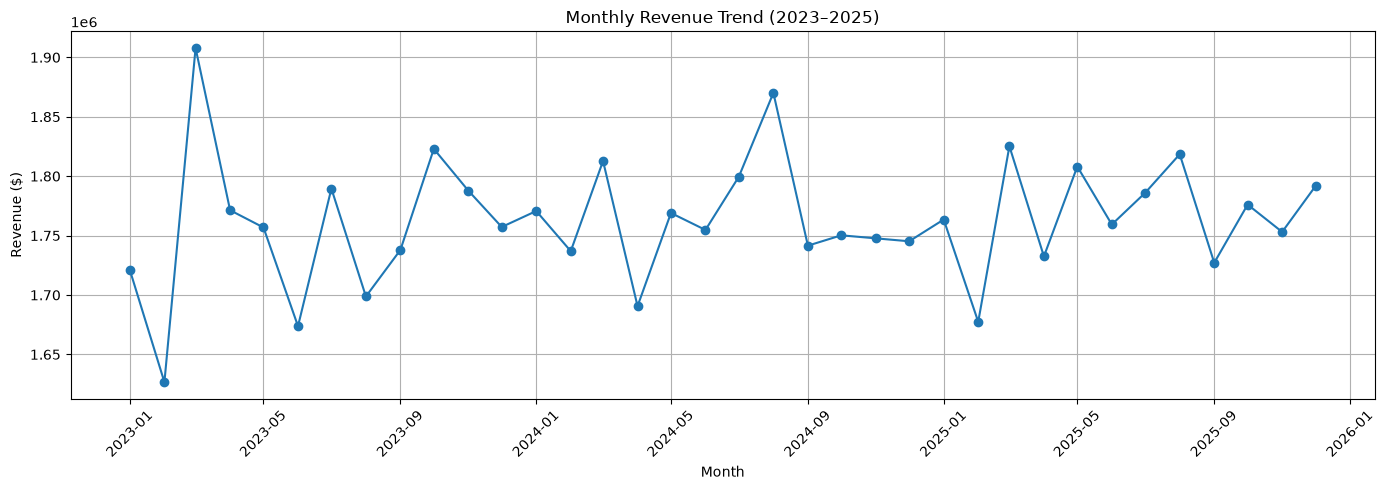

In [110]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend (2023–2025)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [111]:
train = monthly_revenue.iloc[:-6]
test = monthly_revenue.iloc[-6:]

naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index
)

print("Training months:", len(train))
print("Testing months:", len(test))
print("\nActual vs Forecast:")
print(pd.DataFrame({
    "Actual": test,
    "Forecast": naive_forecast
}))

Training months: 30
Testing months: 6

Actual vs Forecast:
                 Actual    Forecast
order_month                        
2025-07-01   1786018.77  1759320.96
2025-08-01   1818446.79  1759320.96
2025-09-01   1727106.92  1759320.96
2025-10-01   1776083.42  1759320.96
2025-11-01   1753054.98  1759320.96
2025-12-01   1791687.69  1759320.96


In [112]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(test, naive_forecast)

rmse = np.sqrt(
    mean_squared_error(test, naive_forecast)
)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 28905.48
RMSE: 33201.98


In [113]:
moving_average_forecast = []

history = list(train)

for actual_value in test:
    prediction = np.mean(history[-3:])
    moving_average_forecast.append(prediction)
    history.append(actual_value)

moving_average_forecast = pd.Series(
    moving_average_forecast,
    index=test.index
)

ma_mae = mean_absolute_error(
    test, moving_average_forecast
)

ma_rmse = np.sqrt(
    mean_squared_error(test, moving_average_forecast)
)

print("Moving Average MAE:", round(ma_mae, 2))
print("Moving Average RMSE:", round(ma_rmse, 2))

Moving Average MAE: 29286.44
Moving Average RMSE: 34719.54


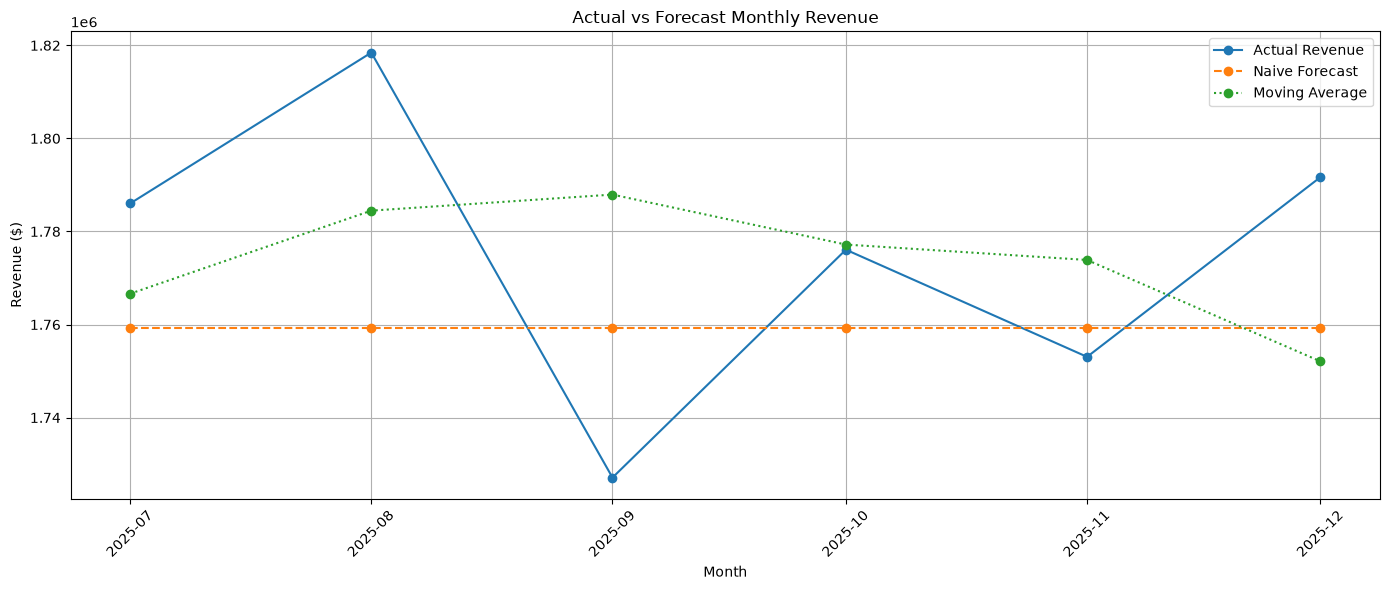

In [114]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test.values,
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    naive_forecast.index,
    naive_forecast.values,
    marker="o",
    linestyle="--",
    label="Naive Forecast"
)

plt.plot(
    moving_average_forecast.index,
    moving_average_forecast.values,
    marker="o",
    linestyle=":",
    label="Moving Average"
)

plt.title("Actual vs Forecast Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [115]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_auc = cross_val_score(
    cv_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

print("Fold ROC-AUC scores:", cv_auc)
print("Average ROC-AUC:", round(cv_auc.mean(), 4))
print("Standard deviation:", round(cv_auc.std(), 4))

Fold ROC-AUC scores: [0.49621629 0.51487764 0.50728229 0.49548978 0.49323157]
Average ROC-AUC: 0.5014
Standard deviation: 0.0083


In [116]:
from sklearn.model_selection import GridSearchCV

In [117]:
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": ["balanced", None]
}

In [118]:
grid_search = GridSearchCV(
    estimator=cv_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X, y)

print("Best parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}
Best CV ROC-AUC: 0.5021


In [119]:
import joblib

best_model = grid_search.best_estimator_

joblib.dump(
    best_model,
    "repeat_purchase_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [120]:
loaded_model = joblib.load(
    "repeat_purchase_model.joblib"
)

print("Loaded model:", type(loaded_model).__name__)

Loaded model: Pipeline
